# Final Paper Analysis - Prediction of Postpartum Hyperketonemia

This notebook consolidates the full analysis pipeline for the manuscript. Every method here was already developed across the project notebooks (`ML Pipeline.ipynb`, `Feature Selection.ipynb`, `selected feature model.ipynb`); this notebook re-organizes them into one clean, reproducible workflow and adds the **new evaluation tables**.

## What this notebook does (in order)

**Part A - Data & feature sets.** Load `Dataset_metabolic_ac.xlsx` and build three feature sets:
- **Metabolites** - the prepartum blood-gas / metabolic panel (15 analytes x 3 weeks) plus per-analyte temporal slopes.
- **Management** - dry-period length, close-up days, parity, and gestation length, each in continuous and threshold-categorical form.
- **Combined** - metabolites + management.

**Part B - Evaluation tables (NEW).** For each feature set, evaluate **4 models** (Logistic Regression, Random Forest, XGBoost, SVM) x **3 imbalance-handling methods** (Baseline, SMOTE, Cost-sensitive) by leave-one-out cross-validation (LOOCV), and report all evaluation metrics in one table per feature set.

**Part C - Feature importance.** Standardized logistic coefficients vs SHAP values (combined set), and a **grouped** importance bar chart (PreP-3 / PreP-2 / PreP-1 / Slope / Management).

**Part D - Forward selection.** Greedy forward selection (by LOOCV PR-AUC) on each feature set, with the selection-path chart. The forward-selected subset of the combined set defines the **Best features** set.

**Part E - Best feature set.** Evaluation table (4 x 3) and a **performance heatmap** for the best feature set.

> **Primary metric:** PR-AUC (area under the precision-recall curve), which is appropriate for imbalanced data. The no-skill baseline equals the outcome prevalence (~0.136).

> **Note on paths:** this notebook lives in a subfolder, so the dataset is read from the parent directory (`../Dataset_metabolic_ac.xlsx`). Figures and tables are written to a local `outputs/` folder.

> **Note on runtime:** the SMOTE-inside-LOOCV evaluations and the forward selection are computationally heavy (several minutes each). Progress is printed as it runs.

In [1]:
# ============================================================================
# IMPORTS
# ============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Models (the 4 model families used throughout the paper)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Preprocessing and pipelines
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline   # pipeline that supports SMOTE
from imblearn.over_sampling import SMOTE

# Validation and metrics
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             accuracy_score, f1_score, matthews_corrcoef,
                             confusion_matrix)
import shap

print('Imports OK')

D:\Softwares\Anaconda\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
D:\Softwares\Anaconda\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Imports OK


In [2]:
# ============================================================================
# CONFIG & AESTHETICS
# ============================================================================
DATA_PATH = '../Dataset_metabolic_ac.xlsx'   # dataset lives one folder up
OUT = 'outputs/'
os.makedirs(OUT, exist_ok=True)

# Consistent colour scheme for temporal / domain groups (matches prior figures)
WEEK_COLORS = {
    'PreP-3':     '#2E86AB',   # blue
    'PreP-2':     '#27AE60',   # green
    'PreP-1':     '#E67E22',   # orange
    'Slope':      '#C0392B',   # red
    'Management': '#8E44AD',   # purple
}
NAVY = '#1A3A5C'

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'axes.grid': True, 'grid.color': '#ECEFF1', 'grid.linewidth': 0.7,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': 'DejaVu Sans', 'font.size': 11,
})

# Model / method grids used everywhere below
MODELS  = ['LR', 'RF', 'XGBoost', 'SVM']
METHODS = ['Baseline', 'SMOTE', 'Cost-sensitive']
MODEL_LABELS = {'LR': 'Logistic Regression', 'RF': 'Random Forest',
                'XGBoost': 'XGBoost', 'SVM': 'SVM (RBF)'}
# Full set of metrics stored in every table (kept complete for later reuse)
METRIC_COLS = ['Accuracy', 'ROC-AUC', 'PR-AUC', 'Sensitivity', 'Specificity', 'PPV', 'NPV', 'F1', 'MCC']
# Heatmap shows a focused subset: drop MCC, add PPV and NPV (per paper request)
HEATMAP_COLS = ['Accuracy', 'ROC-AUC', 'PR-AUC', 'Sensitivity', 'Specificity', 'PPV', 'NPV', 'F1']
print('Config ready. Output folder:', os.path.abspath(OUT))

Config ready. Output folder: D:\DRIVE Lab\metabolic_ketosis_prediction\Final Paper Analysis\outputs


## PART A - Data loading & feature construction

The dataset is in wide format (one row per cow). We define the outcome, then build the three feature sets.

**Outcome (HYK+).** A cow is positive if she tested ketotic at either postpartum test (PP1 or PP2). This matches the definition used throughout the project.

In [3]:
# ----------------------------------------------------------------------------
# A1. Load dataset and define the outcome
# ----------------------------------------------------------------------------
df = pd.read_excel(DATA_PATH)
print('Raw dataset:', df.shape[0], 'rows x', df.shape[1], 'columns')

# HYK+ if positive at PP1 OR PP2 (case/space-robust string handling)
pp1_pos = df['PP1 ketotic?'].str.strip().str.lower() == 'yes'
pp2_pos = df['PP2 ketotic?'].str.strip().str.lower() == 'yes'
y_series = (pp1_pos | pp2_pos).astype(int)
y_series.name = 'HYK_positive'
print('Outcome:', int(y_series.sum()), 'HYK+ |', int((y_series == 0).sum()),
      'HYK- | prevalence =', round(float(y_series.mean()), 3))

Raw dataset: 132 rows x 110 columns
Outcome: 18 HYK+ | 114 HYK- | prevalence = 0.136


In [4]:
# ----------------------------------------------------------------------------
# A2. METABOLITE features - prepartum blood-gas / metabolic panel
# ----------------------------------------------------------------------------
# 15 analytes measured at 3 prepartum weeks. We exclude NEFA (all missing),
# Sample Day (administrative), and any postpartum (PP1/PP2) columns to avoid
# outcome leakage.
WEEKS = ['PreP-3', 'PreP-2', 'PreP-1']
BIO_VARS = ['Urine pH', 'BHBA', 'Glu', 'pH', 'PCO2', 'PO2',
            'BE', 'HCO3', 'TCO2', 'SO2', 'Na', 'K', 'iCa', 'HCT', 'Hgb']

# Locate the column for each (week, analyte), tolerant of leading-space typos
week_cols = {}
for wk in WEEKS:
    cols = []
    for var in BIO_VARS:
        candidates = [wk + ' ' + var, ' ' + wk + ' ' + var, wk + '  ' + var]
        for c in candidates:
            if c in df.columns:
                cols.append(c)
                break
        else:
            matches = [c for c in df.columns if wk in c and var in c
                       and not any(x in c for x in ['ketotic', 'pedro', '2x2', 'Sample', 'NEFA'])]
            if matches:
                cols.append(matches[0])
    week_cols[wk] = list(dict.fromkeys(cols))
    print(wk, ':', len(week_cols[wk]), 'analyte columns found')

# Rename to clean names, e.g. 'PreP-3 Urine pH' -> 'w3_Urine_pH'
rename_map = {}
clean_week_cols = {}
for wk in WEEKS:
    wnum = wk.replace('PreP-', 'w')
    clean_cols = []
    for c in week_cols[wk]:
        new_name = wnum + '_' + c.strip().replace(wk, '').strip().replace(' ', '_')
        rename_map[c] = new_name
        clean_cols.append(new_name)
    clean_week_cols[wk] = clean_cols

df_bio = df[sum(week_cols.values(), [])].rename(columns=rename_map).copy()

PreP-3 : 15 analyte columns found
PreP-2 : 15 analyte columns found
PreP-1 : 15 analyte columns found


In [5]:
# ----------------------------------------------------------------------------
# A3. Slope features - within-cow temporal trend of each analyte
# ----------------------------------------------------------------------------
# For each analyte we fit a straight line across the 3 prepartum weeks
# (x = -3, -2, -1). The slope captures the DIRECTION of change toward calving,
# which can be more informative than any single snapshot. Slopes are part of
# the METABOLITES group.
WEEK_NUMS = {'PreP-3': -3, 'PreP-2': -2, 'PreP-1': -1}
slope_features = {}
for var in BIO_VARS:
    var_by_week = {}
    for wk in WEEKS:
        matching = [c for c in clean_week_cols[wk] if var.replace(' ', '_') in c or var in c]
        if matching:
            var_by_week[wk] = matching[0]
    if len(var_by_week) < 2:
        continue
    slopes = []
    for _, row in df_bio.iterrows():
        wk_nums, vals = [], []
        for wk, col in var_by_week.items():
            v = row[col]
            if pd.notna(v):
                wk_nums.append(WEEK_NUMS[wk])
                vals.append(float(v))
        slopes.append(np.polyfit(wk_nums, vals, 1)[0] if len(wk_nums) >= 2 else np.nan)
    col_name = 'slope_' + var.replace(' ', '_')
    df_bio[col_name] = slopes
    slope_features[var] = col_name
print('Slope features built:', len(slope_features))

Slope features built: 15


In [6]:
# ----------------------------------------------------------------------------
# A4. MANAGEMENT features - continuous + threshold-categorical encodings
# ----------------------------------------------------------------------------
# Each management variable is encoded BOTH continuously (preserves the gradient)
# and categorically (captures threshold effects). We let importance/selection
# decide which form the models actually use.
df_mgmt = pd.DataFrame(index=df.index)

# 1. Total close-up (CU) days - continuous + binary (cut-off 28 d)
df_mgmt['CU_days_cont'] = df['Total CU days']
df_mgmt['CU_days_lt28'] = (df['Total CU days'] < 28).astype(float)

# 2. Total dry days - continuous + categorical (<45, 45-60 [ref], >60)
df_mgmt['dry_days_cont'] = df['total dry days']
df_mgmt['dry_days_lt45'] = (df['total dry days'] < 45).astype(float)
df_mgmt['dry_days_gt60'] = (df['total dry days'] > 60).astype(float)

# 3. Parity (lactation number) - continuous + primiparous flag
df_mgmt['lact_num_cont'] = df['Lact # @ enroll']
df_mgmt['lact_primiparous'] = (df['Lact # @ enroll'] == 1).astype(float)

# 4. Gestation length (days carrying calf at fresh) - continuous + categorical
df_mgmt['dcc_fresh_cont'] = df['dcc @ fresh']
df_mgmt['dcc_fresh_lt266'] = (df['dcc @ fresh'] < 266).astype(float)
df_mgmt['dcc_fresh_gt294'] = (df['dcc @ fresh'] > 294).astype(float)

print('Management features:', df_mgmt.shape[1], 'columns')

Management features: 10 columns


In [7]:
# ----------------------------------------------------------------------------
# A5. Assemble the three feature sets and align with the outcome
# ----------------------------------------------------------------------------
X_metab = df_bio.copy()                              # metabolites (snapshots + slopes)
X_mgmt  = df_mgmt.copy()                             # management (cont + categorical)
X_comb  = pd.concat([df_bio, df_mgmt], axis=1)       # combined

# Keep only cows with a valid outcome
valid = y_series.notna()
X_metab = X_metab.loc[valid].reset_index(drop=True)
X_mgmt  = X_mgmt.loc[valid].reset_index(drop=True)
X_comb  = X_comb.loc[valid].reset_index(drop=True)
y = y_series.loc[valid].values

# The three base feature sets (Best features is added later, after selection)
feature_sets = {'Combined': X_comb, 'Management': X_mgmt, 'Metabolites': X_metab}

# Counts used for cost-sensitive weighting of XGBoost
n_pos = int(y.sum())
n_neg = int((y == 0).sum())

for name, X in feature_sets.items():
    print(name, '->', X.shape[1], 'features')
print('Class balance:', n_pos, 'HYK+ |', n_neg, 'HYK-')

# Helper: assign a feature to a temporal/domain group (for grouped importance)
def get_group(feat):
    if feat.startswith('w3_'):    return 'PreP-3'
    if feat.startswith('w2_'):    return 'PreP-2'
    if feat.startswith('w1_'):    return 'PreP-1'
    if feat.startswith('slope_'): return 'Slope'
    return 'Management'

Combined -> 70 features
Management -> 10 features
Metabolites -> 60 features
Class balance: 18 HYK+ | 114 HYK-


## PART B - Evaluation tables (NEW)

For every feature set we evaluate the full **4 models x 3 methods** grid by LOOCV.

**Models:** Logistic Regression (L2), Random Forest, XGBoost, SVM (RBF).

**Methods (imbalance handling):**
- **Baseline** - the model as-is.
- **SMOTE** - synthetic minority oversampling applied *inside each training fold only* (never to the held-out cow) to avoid leakage.
- **Cost-sensitive** - class weights inversely proportional to class frequency (`class_weight='balanced'`; for XGBoost, `scale_pos_weight = n_neg/n_pos`).

**Validation:** LOOCV with imputation (KNN, k=5) and standardization fit *inside* each fold via a pipeline, so the held-out cow never influences preprocessing.

**Metrics:** Accuracy, ROC-AUC, PR-AUC, Sensitivity, Specificity, F1, and MCC. Threshold-dependent metrics use the Youden-J optimal threshold computed on the out-of-fold predicted probabilities.

In [8]:
# ----------------------------------------------------------------------------
# B1. Build a leakage-free pipeline for any (model, method) combination
# ----------------------------------------------------------------------------
def build_pipeline(model_name, method):
    # Cost-sensitive class weighting (XGBoost handled separately via scale_pos_weight)
    cw = 'balanced' if method == 'Cost-sensitive' else None

    if model_name == 'LR':
        clf = LogisticRegression(penalty='l2', C=0.1, max_iter=3000,
                                 random_state=42, solver='lbfgs', class_weight=cw)
    elif model_name == 'RF':
        clf = RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_leaf=3,
                                     random_state=42, class_weight=cw)
    elif model_name == 'SVM':
        clf = SVC(kernel='rbf', C=1.0, probability=True, random_state=42, class_weight=cw)
    elif model_name == 'XGBoost':
        spw = (n_neg / n_pos) if method == 'Cost-sensitive' else 1.0
        clf = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                            subsample=0.9, eval_metric='logloss', random_state=42,
                            scale_pos_weight=spw, verbosity=0)
    else:
        raise ValueError('unknown model: ' + model_name)

    # Impute + scale always (harmless for trees, required for LR/SVM)
    steps = [('imputer', KNNImputer(n_neighbors=5)), ('scaler', StandardScaler())]
    if method == 'SMOTE':
        # SMOTE only resamples during fit (training fold) -> no leakage
        steps.append(('smote', SMOTE(k_neighbors=5, random_state=42)))
        return ImbPipeline(steps + [('clf', clf)])
    return Pipeline(steps + [('clf', clf)])

In [9]:
# ----------------------------------------------------------------------------
# B2. LOOCV evaluation -> dictionary of metrics
# ----------------------------------------------------------------------------
def evaluate(X, model_name, method):
    pipe = build_pipeline(model_name, method)
    # Out-of-fold positive-class probabilities (leakage-free)
    oof = cross_val_predict(pipe, X.values, y, cv=LeaveOneOut(),
                            method='predict_proba')[:, 1]
    roc = roc_auc_score(y, oof)
    pr  = average_precision_score(y, oof)
    # Youden-J optimal threshold from the ROC curve
    fpr, tpr, thr = roc_curve(y, oof)
    t = thr[np.argmax(tpr - fpr)]
    yp = (oof >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yp).ravel()
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0   # = recall (positive class)
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    ppv  = tp / (tp + fp) if (tp + fp) > 0 else 0.0   # positive predictive value (precision)
    npv  = tn / (tn + fn) if (tn + fn) > 0 else 0.0   # negative predictive value
    return {
        'Accuracy':    accuracy_score(y, yp),
        'ROC-AUC':     roc,
        'PR-AUC':      pr,
        'Sensitivity': sens,
        'Specificity': spec,
        'PPV':         ppv,
        'NPV':         npv,
        'F1':          f1_score(y, yp, zero_division=0),
        'MCC':         matthews_corrcoef(y, yp),
    }

# Build the full 4x3 table for a feature set
def build_table(X, set_name):
    print('=' * 70)
    print('Evaluating feature set:', set_name, '(', X.shape[1], 'features )')
    print('=' * 70)
    rows = []
    for m in MODELS:
        for meth in METHODS:
            res = evaluate(X, m, meth)
            rows.append({'Model': MODEL_LABELS[m], 'Method': meth, **res})
            print('  %-20s %-15s PR-AUC=%.3f  ROC=%.3f  Sens=%.3f  Spec=%.3f'
                  % (MODEL_LABELS[m], meth, res['PR-AUC'], res['ROC-AUC'],
                     res['Sensitivity'], res['Specificity']))
    tbl = pd.DataFrame(rows)
    for c in METRIC_COLS:
        tbl[c] = tbl[c].round(3)
    return tbl

In [10]:
# ----------------------------------------------------------------------------
# B3. Run the evaluation for the three base feature sets
#     (this is the heavy step - several minutes)
# ----------------------------------------------------------------------------
tables = {}
for set_name in ['Combined', 'Management', 'Metabolites']:
    tables[set_name] = build_table(feature_sets[set_name], set_name)

prevalence = float(y.mean())
print('\nNo-skill PR-AUC baseline (prevalence):', round(prevalence, 3))

Evaluating feature set: Combined ( 70 features )
  Logistic Regression  Baseline        PR-AUC=0.277  ROC=0.595  Sens=0.389  Spec=0.851
  Logistic Regression  SMOTE           PR-AUC=0.342  ROC=0.588  Sens=0.389  Spec=0.851
  Logistic Regression  Cost-sensitive  PR-AUC=0.296  ROC=0.584  Sens=0.667  Spec=0.561
  Random Forest        Baseline        PR-AUC=0.230  ROC=0.607  Sens=0.500  Spec=0.781
  Random Forest        SMOTE           PR-AUC=0.195  ROC=0.602  Sens=0.500  Spec=0.781
  Random Forest        Cost-sensitive  PR-AUC=0.150  ROC=0.516  Sens=0.556  Spec=0.658
  XGBoost              Baseline        PR-AUC=0.154  ROC=0.542  Sens=0.611  Spec=0.588
  XGBoost              SMOTE           PR-AUC=0.168  ROC=0.538  Sens=0.500  Spec=0.763
  XGBoost              Cost-sensitive  PR-AUC=0.147  ROC=0.510  Sens=0.611  Spec=0.518
  SVM (RBF)            Baseline        PR-AUC=0.082  ROC=0.140  Sens=0.000  Spec=1.000
  SVM (RBF)            SMOTE           PR-AUC=0.139  ROC=0.345  Sens=0.167  Spec=

In [11]:
# ----------------------------------------------------------------------------
# B4. Display & save the tables. Index = (Model, Method) so each model spans
#     its 3 methods, exactly as requested for the paper table.
# ----------------------------------------------------------------------------
def show_and_save(tbl, set_name):
    disp = tbl.set_index(['Model', 'Method'])
    fname = OUT + 'table_' + set_name.replace(' ', '_').lower() + '.csv'
    tbl.to_csv(fname, index=False)
    print('\n############ TABLE -', set_name, '############')
    print(disp.to_string())
    print('saved ->', fname)
    return disp

for set_name in ['Combined', 'Management', 'Metabolites']:
    show_and_save(tables[set_name], set_name)


############ TABLE - Combined ############
                                    Accuracy  ROC-AUC  PR-AUC  Sensitivity  Specificity    PPV    NPV     F1    MCC
Model               Method                                                                                         
Logistic Regression Baseline           0.788    0.595   0.277        0.389        0.851  0.292  0.898  0.333  0.213
                    SMOTE              0.788    0.588   0.342        0.389        0.851  0.292  0.898  0.333  0.213
                    Cost-sensitive     0.576    0.584   0.296        0.667        0.561  0.194  0.914  0.300  0.157
Random Forest       Baseline           0.742    0.607   0.230        0.500        0.781  0.265  0.908  0.346  0.220
                    SMOTE              0.742    0.602   0.195        0.500        0.781  0.265  0.908  0.346  0.220
                    Cost-sensitive     0.644    0.516   0.150        0.556        0.658  0.204  0.904  0.299  0.152
XGBoost             Baseline

## PART C - Feature importance

Two complementary views on the **combined** feature set, using an L2-penalized logistic model (interpretable and stable under regularization):
- **Standardized coefficients** - the model weight on the log-odds of HYK (features are standardized, so magnitudes are comparable).
- **SHAP values** - per-cow contributions that account for the data distribution and share credit among correlated features.

Agreement between the two is evidence of a robust finding. We then **group** SHAP importance by temporal/domain group (PreP-3 / PreP-2 / PreP-1 / Slope / Management).

In [12]:
# ----------------------------------------------------------------------------
# C1. Fit L2 logistic on the full combined set (imputed + scaled) for importance
# ----------------------------------------------------------------------------
all_feature_cols = X_comb.columns.tolist()
X_imp = KNNImputer(n_neighbors=5).fit_transform(X_comb.values)
X_sc  = StandardScaler().fit_transform(X_imp)

lr_full = LogisticRegression(penalty='l2', C=0.1, max_iter=3000,
                             random_state=42, solver='lbfgs').fit(X_sc, y)

coef_df = pd.DataFrame({
    'Feature': all_feature_cols,
    'Coefficient': lr_full.coef_[0],
    'Abs_coef': np.abs(lr_full.coef_[0]),
}).sort_values('Abs_coef', ascending=False).reset_index(drop=True)
coef_df['Group'] = coef_df['Feature'].apply(get_group)

# SHAP (exact linear explainer for a linear model)
explainer = shap.LinearExplainer(lr_full, X_sc, feature_names=all_feature_cols)
shap_values = explainer(X_sc)
mean_shap = pd.DataFrame({
    'Feature': all_feature_cols,
    'Mean_SHAP': np.abs(shap_values.values).mean(axis=0),
    'Group': [get_group(f) for f in all_feature_cols],
}).sort_values('Mean_SHAP', ascending=False).reset_index(drop=True)

print('Top 10 features by mean |SHAP|:')
print(mean_shap.head(10).to_string(index=False))

Background dataset has 132 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=132 when initializing the masker.


Top 10 features by mean |SHAP|:
      Feature  Mean_SHAP      Group
dry_days_gt60   0.386766 Management
dry_days_cont   0.360126 Management
       w1_SO2   0.195646     PreP-1
 CU_days_lt28   0.141118 Management
       w3_Glu   0.137647     PreP-3
        w3_pH   0.128137     PreP-3
  w3_Urine_pH   0.126991     PreP-3
       w3_SO2   0.121380     PreP-3
    slope_iCa   0.110787      Slope
 CU_days_cont   0.105180 Management


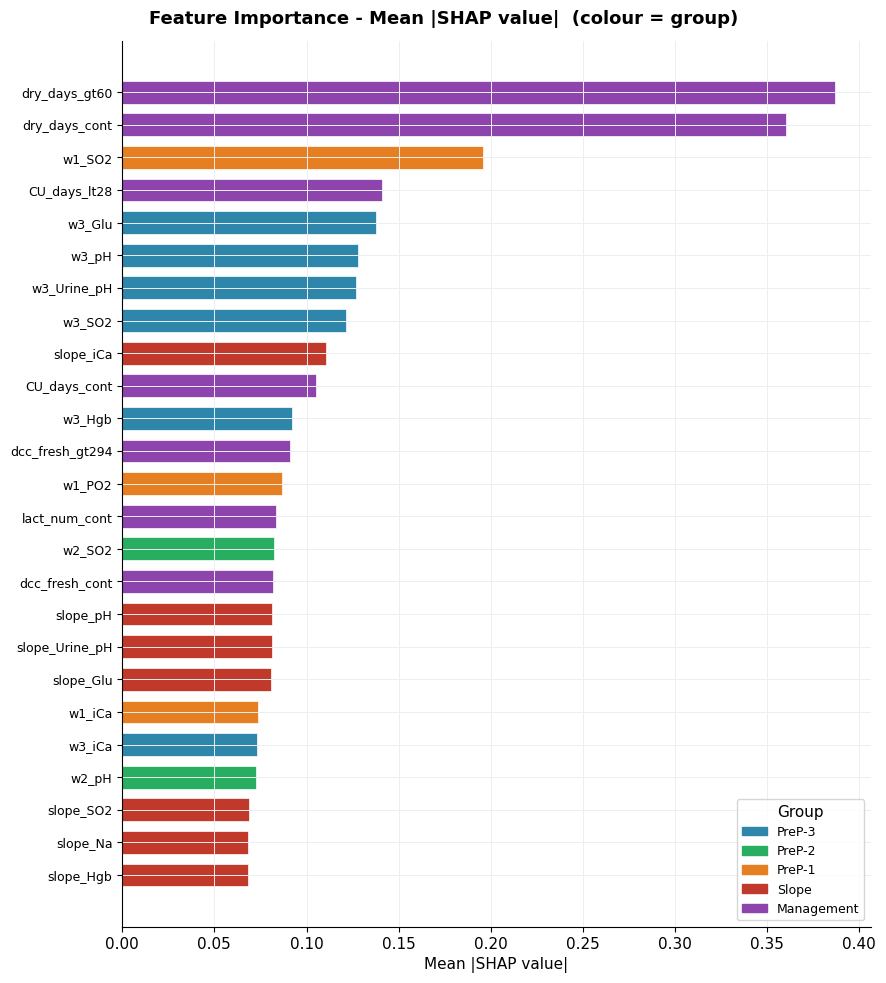

saved -> fig_feature_importance_shap.png


In [13]:
# ----------------------------------------------------------------------------
# C2. FIGURE - Feature importance by SHAP (top 25)
#     SHAP-only: the LR-coefficient panel was removed per the paper request,
#     because SHAP gives a single, model-faithful importance ranking.
# ----------------------------------------------------------------------------
TOP_N = 25
top_shap = mean_shap.head(TOP_N)

fig, ax = plt.subplots(figsize=(9, 10))
fig.suptitle('Feature Importance - Mean |SHAP value|  (colour = group)',
             fontsize=13, fontweight='bold')
colors = [WEEK_COLORS[g] for g in top_shap['Group']]
ax.barh(range(len(top_shap)), top_shap['Mean_SHAP'].values, color=colors,
        edgecolor='white', linewidth=0.5, height=0.7)
ax.set_yticks(range(len(top_shap)))
ax.set_yticklabels(top_shap['Feature'], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Mean |SHAP value|', fontsize=11)
handles = [mpatches.Patch(color=v, label=k) for k, v in WEEK_COLORS.items()]
ax.legend(handles=handles, loc='lower right', fontsize=9, title='Group')
plt.tight_layout()
plt.savefig(OUT + 'fig_feature_importance_shap.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close()
print('saved -> fig_feature_importance_shap.png')

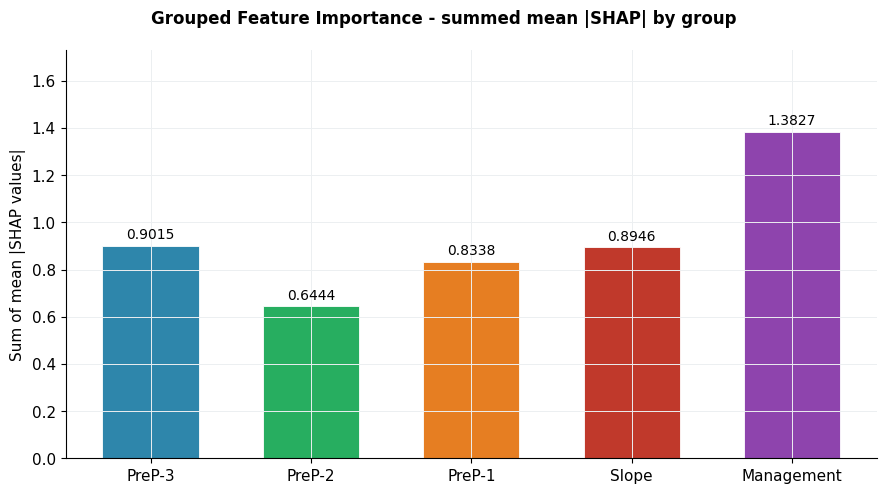

saved -> fig_group_importance.png


In [14]:
# ----------------------------------------------------------------------------
# C3. FIGURE - Grouped feature importance (Slope / PreP weeks / Management)
# ----------------------------------------------------------------------------
# Sum mean |SHAP| within each group to answer: which category contributes most?
group_order = ['PreP-3', 'PreP-2', 'PreP-1', 'Slope', 'Management']
group_shap = (mean_shap.groupby('Group')['Mean_SHAP'].sum()
              .reindex(group_order).fillna(0))

fig, ax = plt.subplots(figsize=(9, 5))
fig.suptitle('Grouped Feature Importance - summed mean |SHAP| by group',
             fontsize=12, fontweight='bold')
colors_g = [WEEK_COLORS[g] for g in group_shap.index]
bars = ax.bar(group_shap.index, group_shap.values, color=colors_g,
              edgecolor='white', linewidth=0.6, width=0.6)
ax.bar_label(bars, fmt='%.4f', fontsize=10, padding=3)
ax.set_ylabel('Sum of mean |SHAP values|')
ax.set_ylim(0, group_shap.max() * 1.25)
plt.tight_layout()
plt.savefig(OUT + 'fig_group_importance.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close()
print('saved -> fig_group_importance.png')

## PART D - Forward selection

Greedy forward selection: starting from no features, at each step we add the single feature that most increases LOOCV PR-AUC, stopping when the gain falls below a small tolerance. Selection uses the **L2 logistic** model (fast and interpretable), consistent with the project's prior approach.

We run forward selection on each base feature set and plot all selection paths together. The forward-selected subset of the **Combined** set defines the **Best features** set used in Part E.

> This step is the slowest part of the notebook because each candidate evaluation is a full LOOCV. Progress is printed per step.

In [15]:
# ----------------------------------------------------------------------------
# D1. Forward selection by LOOCV PR-AUC (L2 logistic)
# ----------------------------------------------------------------------------
def lr_pr_auc(Xsub):
    pipe = Pipeline([('imputer', KNNImputer(n_neighbors=5)),
                     ('scaler', StandardScaler()),
                     ('clf', LogisticRegression(penalty='l2', C=0.1, max_iter=3000,
                                                random_state=42, solver='lbfgs'))])
    oof = cross_val_predict(pipe, Xsub.values, y, cv=LeaveOneOut(),
                            method='predict_proba')[:, 1]
    return average_precision_score(y, oof)

def forward_select(X, set_name, max_steps=8, tol=0.002):
    print('Forward selection on', set_name, '...')
    remaining = list(X.columns)
    selected, path = [], [float(y.mean())]   # start at the no-skill baseline
    for step in range(max_steps):
        best_pr, best_feat = -1, None
        for f in remaining:
            pr = lr_pr_auc(X[selected + [f]])
            if pr > best_pr:
                best_pr, best_feat = pr, f
        if best_feat is None:
            break
        if step > 0 and best_pr - path[-1] < tol:
            print('  step', step + 1, ': gain < tol, stopping')
            break
        selected.append(best_feat)
        remaining.remove(best_feat)
        path.append(best_pr)
        print('  step %d: + %-24s PR-AUC=%.4f' % (step + 1, best_feat, best_pr))
    return selected, path

fwd_results = {}
for set_name in ['Combined', 'Management', 'Metabolites']:
    sel, path = forward_select(feature_sets[set_name], set_name)
    fwd_results[set_name] = {'selected': sel, 'path': path}

# The overall Best features set = forward-selected subset of the Combined set
BEST_FEATURES = fwd_results['Combined']['selected']
print('\nBest features (from Combined):', BEST_FEATURES)

Forward selection on Combined ...
  step 1: + dry_days_cont            PR-AUC=0.4665
  step 2: + w2_BE                    PR-AUC=0.4828
  step 3: + w1_HCT                   PR-AUC=0.4935
  step 4: + dry_days_gt60            PR-AUC=0.4974
  step 5: + slope_Glu                PR-AUC=0.5002
  step 6: + dcc_fresh_cont           PR-AUC=0.5078
  step 7: + dry_days_lt45            PR-AUC=0.5104
  step 8 : gain < tol, stopping
Forward selection on Management ...
  step 1: + dry_days_cont            PR-AUC=0.4665
  step 2: + dry_days_lt45            PR-AUC=0.4698
  step 3: + dcc_fresh_gt294          PR-AUC=0.4751
  step 4: + dcc_fresh_lt266          PR-AUC=0.4816
  step 5 : gain < tol, stopping
Forward selection on Metabolites ...
  step 1: + slope_iCa                PR-AUC=0.1657
  step 2: + w3_pH                    PR-AUC=0.1717
  step 3: + w1_HCT                   PR-AUC=0.1778
  step 4 : gain < tol, stopping

Best features (from Combined): ['dry_days_cont', 'w2_BE', 'w1_HCT', 'dry_days_gt60

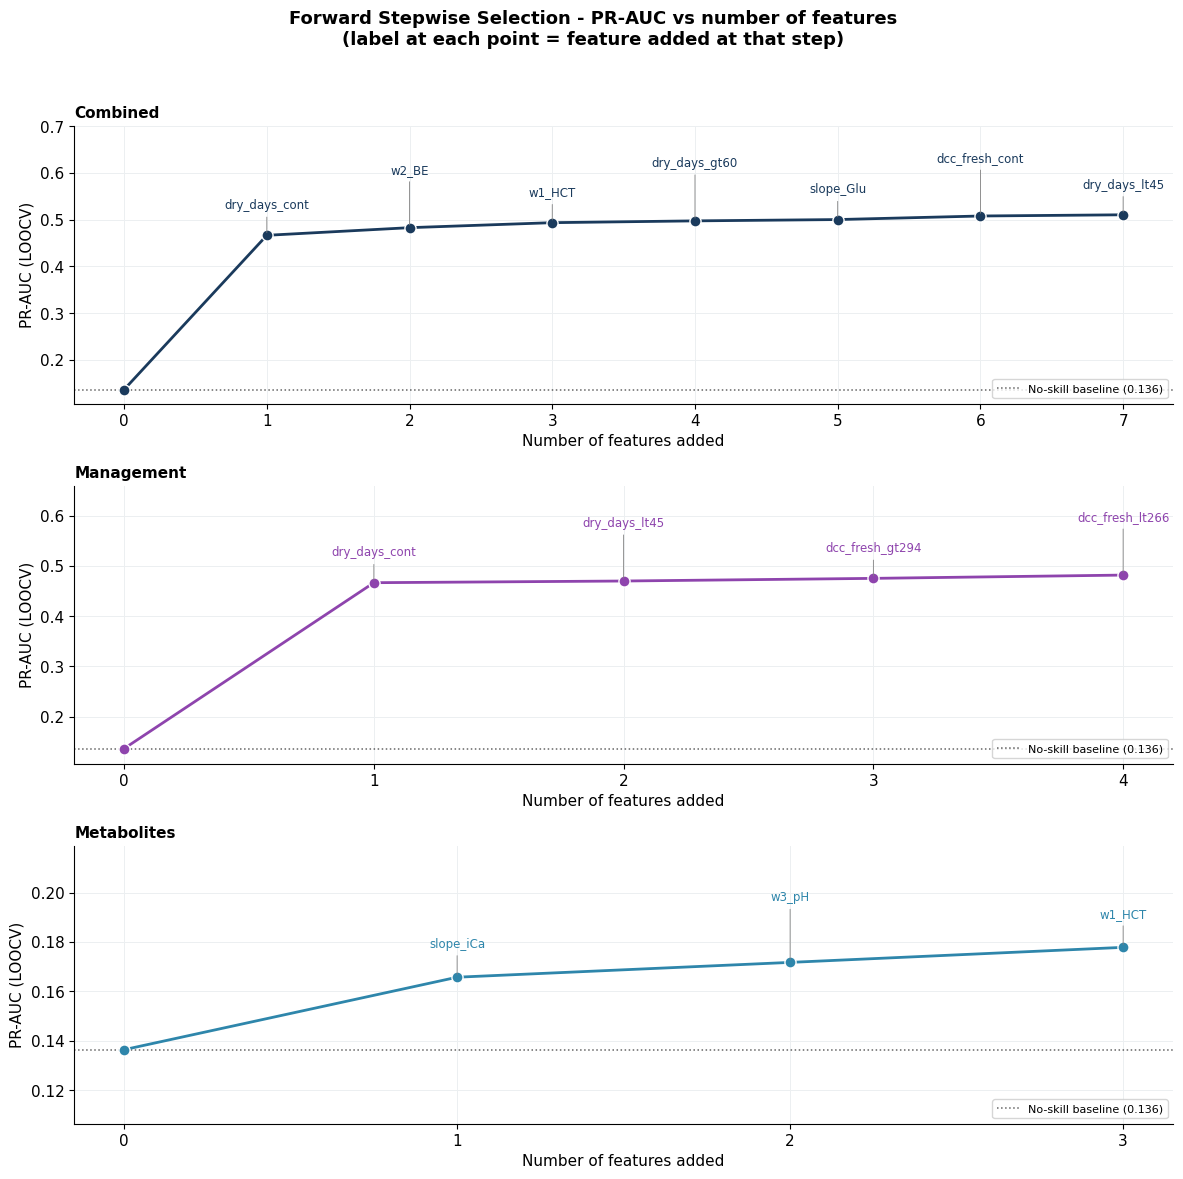

saved -> fig_forward_selection.png


In [ ]:
# ----------------------------------------------------------------------------
# D2. FIGURE - Forward selection paths, labelled with the feature added
#     One panel per feature set so labels never cross between sets; within a
#     panel the labels alternate height (with a thin leader line) to avoid
#     overlapping one another.
# ----------------------------------------------------------------------------
set_colors = {'Combined': NAVY, 'Management': '#8E44AD', 'Metabolites': '#2E86AB'}
sets_plot = ['Combined', 'Management', 'Metabolites']

fig, axes = plt.subplots(len(sets_plot), 1, figsize=(12, 12))
fig.suptitle('Forward Stepwise Selection - PR-AUC vs number of features\n'
             '(label at each point = feature added at that step)',
             fontsize=13, fontweight='bold')

for ax, set_name in zip(axes, sets_plot):
    path = fwd_results[set_name]['path']          # path[0] = baseline (0 features)
    selected = fwd_results[set_name]['selected']  # one name per added feature
    xs = list(range(len(path)))
    ax.plot(xs, path, marker='o', color=set_colors[set_name],
            lw=2, markersize=8, markeredgecolor='white', zorder=3)
    ax.axhline(prevalence, color='black', lw=1.1, linestyle=':', alpha=0.6,
               label='No-skill baseline (%.3f)' % prevalence)

    pr_span = (max(path) - min(path)) or 0.1
    for i, feat in enumerate(selected):
        xpt, ypt = i + 1, path[i + 1]
        dy = (0.12 if i % 2 == 0 else 0.26) * (pr_span + 0.05)   # alternate label height
        ax.annotate(feat, (xpt, ypt), xytext=(xpt, ypt + dy),
                    ha='center', va='bottom', fontsize=8.5,
                    color=set_colors[set_name],
                    arrowprops=dict(arrowstyle='-', color='grey', lw=0.6))

    ax.set_title(set_name, fontweight='bold', fontsize=11, loc='left')
    ax.set_ylabel('PR-AUC (LOOCV)')
    ax.set_xlabel('Number of features added')
    ax.set_xticks(xs)
    ax.set_ylim(min(path) - 0.03, max(path) + 0.45 * (pr_span + 0.05))
    ax.legend(fontsize=8, loc='lower right')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(OUT + 'fig_forward_selection.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close()
print('saved -> fig_forward_selection.png')

## PART E - Best feature set: table & performance heatmap

We now evaluate the full 4 models x 3 methods grid on the **Best features** set (the fourth table), and visualize all metrics as a **performance heatmap** (same style as the project heatmap).

In [17]:
# ----------------------------------------------------------------------------
# E1. Evaluation table for the Best features set (4th table)
# ----------------------------------------------------------------------------
X_best = X_comb[BEST_FEATURES]
feature_sets['Best features'] = X_best
tables['Best features'] = build_table(X_best, 'Best features')
show_and_save(tables['Best features'], 'Best features')

  Random Forest        SMOTE           PR-AUC=0.410  ROC=0.763  Sens=0.722  Spec=0.789
  Random Forest        Cost-sensitive  PR-AUC=0.350  ROC=0.734  Sens=0.778  Spec=0.693
  XGBoost              Baseline        PR-AUC=0.278  ROC=0.651  Sens=0.722  Spec=0.614
  XGBoost              SMOTE           PR-AUC=0.367  ROC=0.696  Sens=0.556  Spec=0.825
  XGBoost              Cost-sensitive  PR-AUC=0.282  ROC=0.628  Sens=0.667  Spec=0.632
  SVM (RBF)            Baseline        PR-AUC=0.084  ROC=0.173  Sens=0.000  Spec=1.000
  SVM (RBF)            SMOTE           PR-AUC=0.424  ROC=0.734  Sens=0.778  Spec=0.825
  SVM (RBF)            Cost-sensitive  PR-AUC=0.330  ROC=0.701  Sens=0.778  Spec=0.816

############ TABLE - Best features ############
                                    Accuracy  ROC-AUC  PR-AUC  Sensitivity  Specificity    PPV    NPV     F1    MCC
Model               Method                                                                                         
Logistic Regression Bas

Accuracy  ROC-AUC  PR-AUC  Sensitivity  \
Model               Method                                                   
Logistic Regression Baseline           0.765    0.763   0.510        0.778   
                    SMOTE              0.735    0.740   0.498        0.778   
                    Cost-sensitive     0.735    0.749   0.501        0.778   
Random Forest       Baseline           0.826    0.741   0.387        0.667   
                    SMOTE              0.780    0.763   0.410        0.722   
                    Cost-sensitive     0.705    0.734   0.350        0.778   
XGBoost             Baseline           0.629    0.651   0.278        0.722   
                    SMOTE              0.788    0.696   0.367        0.556   
                    Cost-sensitive     0.636    0.628   0.282        0.667   
SVM (RBF)           Baseline           0.864    0.173   0.084        0.000   
                    SMOTE              0.818    0.734   0.424        0.778   
                    Cost-sensitive     0.811    0.701   0.330        0.778   

                                    Specificity    PPV    NPV     F1    MCC  
Model               Method                                                   
Logistic Regression Baseline              0.763  0.341  0.956  0.475  0.401  
                    SMOTE                 0.728  0.311  0.954  0.444  0.366  
                    Cost-sensitive        0.728  0.311  0.954  0.444  0.366  
Random Forest       Baseline              0.851  0.414  0.942  0.511  0.429  
                    SMOTE                 0.789  0.351  0.947  0.473  0.391  
                    Cost-sensitive        0.693  0.286  0.952  0.418  0.334  
XGBoost             Baseline              0.614  0.228  0.933  0.347  0.233  
                    SMOTE                 0.825  0.333  0.922  0.417  0.311  
                    Cost-sensitive        0.632  0.222  0.923  0.333  0.208  
SVM (RBF)           Baseline              1.000  0.000  0.864  0.000  0.000  
                    SMOTE                 0.825  0.412  0.959  0.538  0.473  
                    Cost-sensitive        0.816  0.400  0.959  0.528  0.461

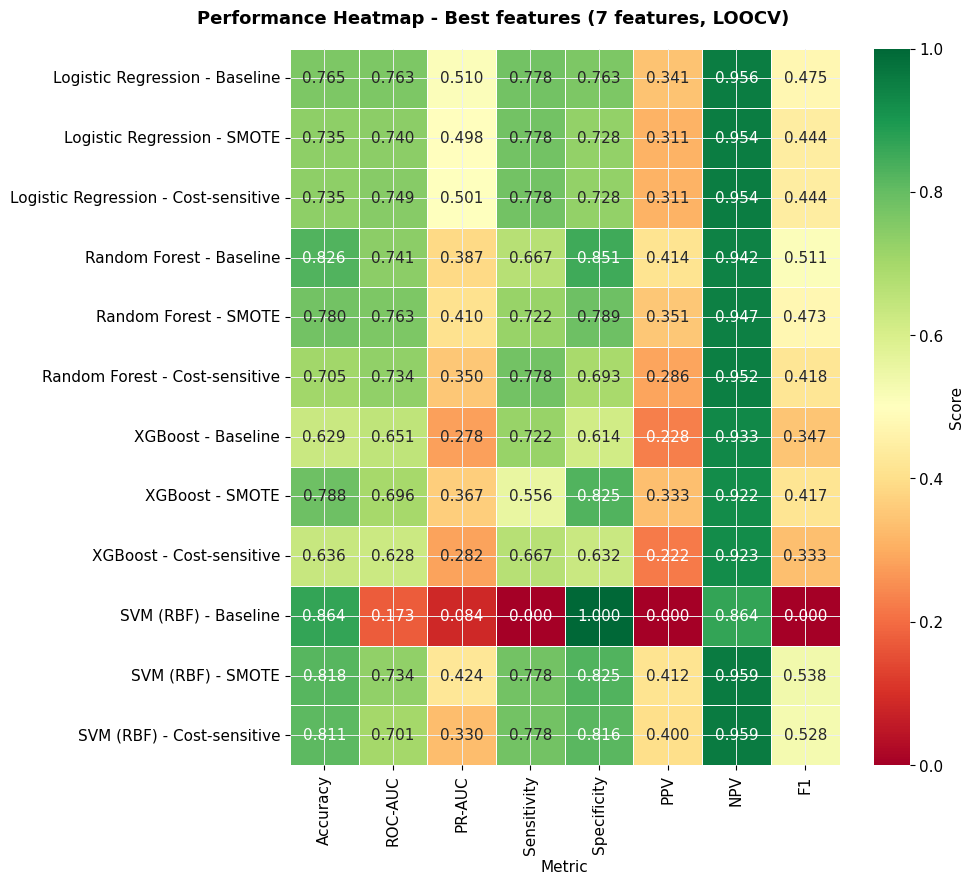

saved -> fig_heatmap_best.png


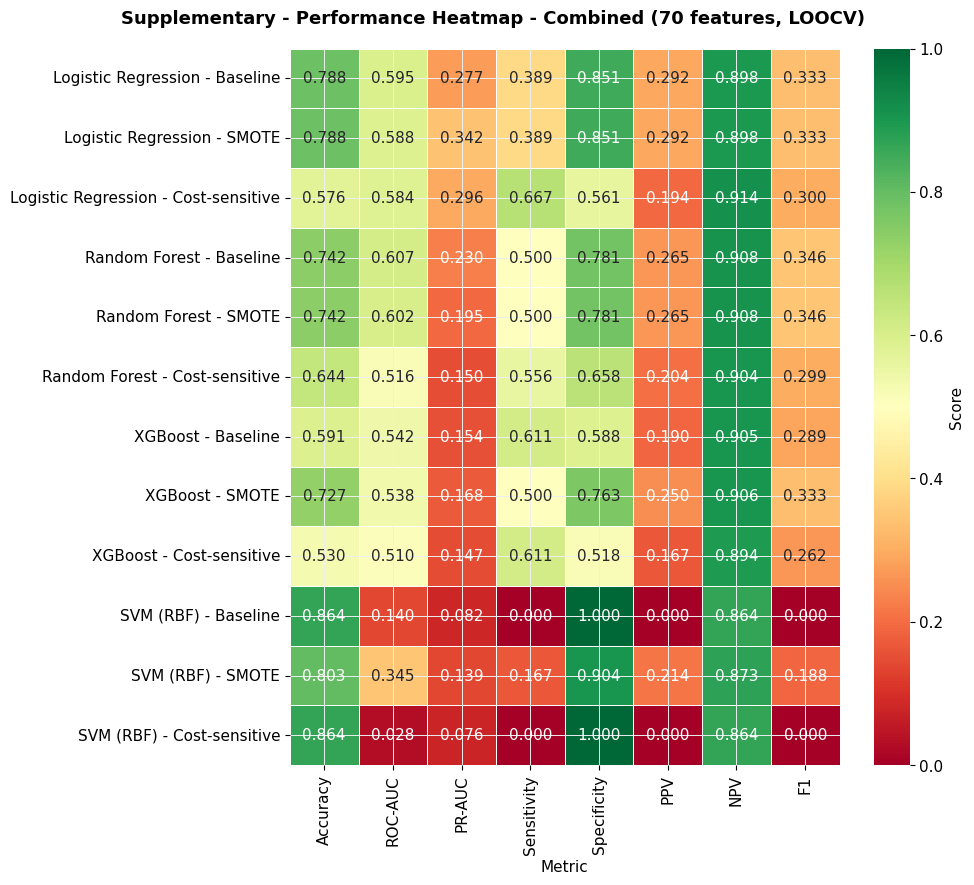

saved -> fig_heatmap_all70.png


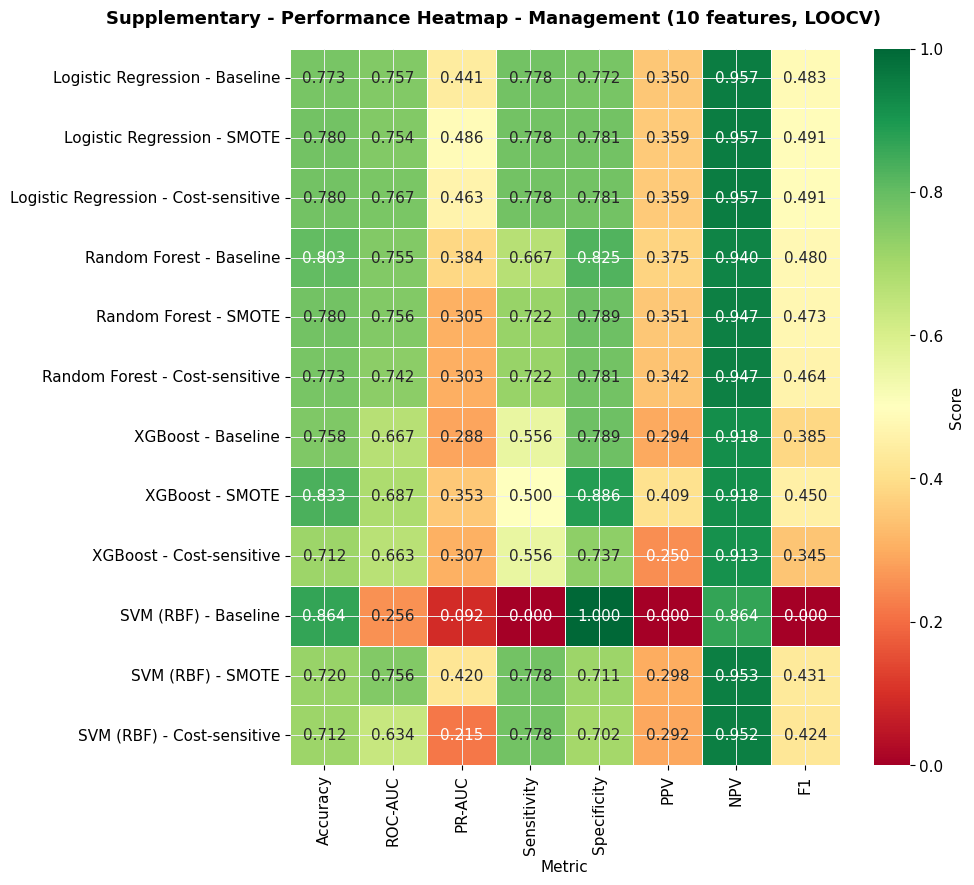

saved -> fig_heatmap_management.png


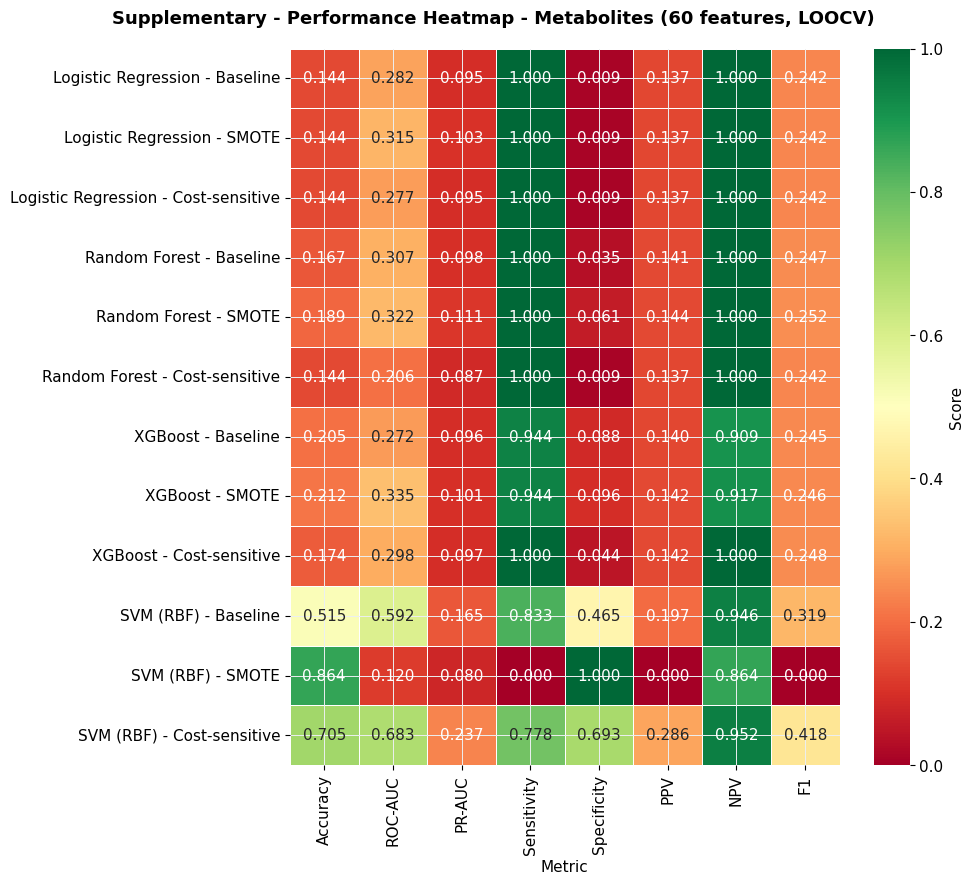

saved -> fig_heatmap_metabolites.png


In [18]:
# ----------------------------------------------------------------------------
# E2. FIGURE - Performance heatmaps for ALL feature sets
#     Rows = model x method (12 combos); Columns = HEATMAP_COLS
#     (Accuracy, ROC-AUC, PR-AUC, Sensitivity, Specificity, PPV, NPV, F1).
#     Best feature set = main figure; the other three = supplementary material.
# ----------------------------------------------------------------------------
def plot_perf_heatmap(set_name, fname_tag, supplementary=False):
    tbl = tables[set_name].copy()
    tbl['Label'] = tbl['Model'] + ' - ' + tbl['Method']
    plot_df = tbl.set_index('Label')[HEATMAP_COLS]
    n_feat = feature_sets[set_name].shape[1]
    tag = 'Supplementary - ' if supplementary else ''

    fig, ax = plt.subplots(figsize=(10, 9))
    fig.suptitle('%sPerformance Heatmap - %s (%d features, LOOCV)'
                 % (tag, set_name, n_feat), fontsize=13, fontweight='bold')
    sns.heatmap(plot_df.astype(float), annot=True, fmt='.3f', cmap='RdYlGn',
                linewidths=0.5, linecolor='white', cbar_kws={'label': 'Score'}, ax=ax)
    ax.set_ylabel('')
    ax.set_xlabel('Metric')
    plt.tight_layout()
    out_name = 'fig_heatmap_' + fname_tag + '.png'
    plt.savefig(OUT + out_name, dpi=200, bbox_inches='tight')
    plt.show()
    plt.close()
    print('saved ->', out_name)

# Main figure: best feature set
plot_perf_heatmap('Best features', 'best', supplementary=False)
# Supplementary figures: all 70, just management, just metabolites
plot_perf_heatmap('Combined',    'all70',       supplementary=True)
plot_perf_heatmap('Management',  'management',  supplementary=True)
plot_perf_heatmap('Metabolites', 'metabolites', supplementary=True)

In [19]:
# ----------------------------------------------------------------------------
# E3. MASTER RESULTS TABLE - every feature set x model x method in one place.
#     This is the single source of truth: to build ANY paper/supplementary
#     table later, just slice `all_results` (or read all_results_master.csv)
#     instead of re-running the models.
# ----------------------------------------------------------------------------
ALL_SETS = ['Combined', 'Management', 'Metabolites', 'Best features']

# Long-format master table: one row per (feature set, model, method)
all_results = pd.concat(
    [tables[s].assign(FeatureSet=s) for s in ALL_SETS],
    ignore_index=True
)
all_results = all_results[['FeatureSet', 'Model', 'Method'] + METRIC_COLS]

# Save the master table (CSV) + a workbook with a Master sheet and per-set sheets
all_results.to_csv(OUT + 'all_results_master.csv', index=False)
with pd.ExcelWriter(OUT + 'all_evaluation_tables.xlsx') as writer:
    all_results.to_excel(writer, sheet_name='Master', index=False)
    for set_name in ALL_SETS:
        tables[set_name].set_index(['Model', 'Method']).to_excel(
            writer, sheet_name=set_name[:31])

print('saved -> all_results_master.csv  (', all_results.shape[0], 'rows )')
print('saved -> all_evaluation_tables.xlsx  (Master + 4 per-set sheets)')

# Quick reference - how to pull values later without re-running anything:
#   all_results.query("FeatureSet == 'Best features' and Method == 'SMOTE'")
#   all_results.loc[all_results['Model'] == 'Logistic Regression', ['FeatureSet','Method','PR-AUC','PPV','NPV']]
print('\nMaster results table (head):')
print(all_results.head(12).to_string(index=False))
print('\nAll outputs written to:', os.path.abspath(OUT))

saved -> all_results_master.csv  ( 48 rows )
saved -> all_evaluation_tables.xlsx  (Master + 4 per-set sheets)

Master results table (head):
FeatureSet               Model         Method  Accuracy  ROC-AUC  PR-AUC  Sensitivity  Specificity   PPV   NPV    F1   MCC
  Combined Logistic Regression       Baseline     0.788    0.595   0.277        0.389        0.851 0.292 0.898 0.333 0.213
  Combined Logistic Regression          SMOTE     0.788    0.588   0.342        0.389        0.851 0.292 0.898 0.333 0.213
  Combined Logistic Regression Cost-sensitive     0.576    0.584   0.296        0.667        0.561 0.194 0.914 0.300 0.157
  Combined       Random Forest       Baseline     0.742    0.607   0.230        0.500        0.781 0.265 0.908 0.346 0.220
  Combined       Random Forest          SMOTE     0.742    0.602   0.195        0.500        0.781 0.265 0.908 0.346 0.220
  Combined       Random Forest Cost-sensitive     0.644    0.516   0.150        0.556        0.658 0.204 0.904 0.299 0.152

## Summary of outputs

**Tables (the new deliverable)** - `outputs/table_*.csv`, `outputs/all_results_master.csv`, `outputs/all_evaluation_tables.xlsx`:
- One table per feature set (**Combined / all 70**, **Management**, **Metabolites**, **Best features**).
- Rows: 4 models x 3 methods. Columns: Accuracy, ROC-AUC, PR-AUC, Sensitivity, Specificity, PPV, NPV, F1, MCC.
- **`all_results_master.csv`** is the single source of truth: every feature set x model x method in one long table. Slice it (or the in-memory `all_results` DataFrame) to build any later table without re-running the models.

**Figures** - `outputs/`:
- `fig_feature_importance_shap.png` - SHAP importance (top 25; coefficient panel removed).
- `fig_group_importance.png` - grouped importance (PreP weeks / Slope / Management).
- `fig_forward_selection.png` - forward-selection PR-AUC paths, labelled with the feature added at each step.
- `fig_heatmap_best.png` - **main** performance heatmap (best feature set), metrics include PPV/NPV (no MCC).
- `fig_heatmap_all70.png`, `fig_heatmap_management.png`, `fig_heatmap_metabolites.png` - **supplementary** heatmaps for the other three feature sets.

**Notes / things you may want to adjust:**
- *Best features* is defined as the forward-selected subset of the Combined set. If you would rather define it differently (e.g., the union of per-set selections, or a fixed expert-chosen list), set `BEST_FEATURES` manually before Part E.
- Forward selection uses the L2 logistic model for speed/interpretability (as in the prior notebooks). If you want it model-agnostic, swap `lr_pr_auc` for another estimator.
- Model hyperparameters mirror the project notebooks; adjust in `build_pipeline` if needed.